# Agricultural Yield Prediction and Productivity Factor Analysis
**Goal:** estimate crop yield from historical agricultural and environmental data, identify the crop,
geographic, temporal and weather predictors, compare regression algorithms, and analyse where the model is least certain.

**Data:** FAOSTAT crop production (QCL) joined with FAOSTAT temperature change, by country and year.

In [3]:
import pandas as pd
crops = pd.read_csv("india_china_cleaned.csv")
weather = pd.read_csv("weather_cleaned_5countries.csv")
print(crops.shape, weather.shape)

(11809, 12) (325, 12)


In [4]:
#onlu india and china for prediction 
weather = weather[weather["country"].isin(["India", "China"])]

In [5]:
print(crops.columns.tolist())

['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha', 'production_t', 'yield_flag', 'temp_change_annual_c', 'temp_change_djf_c', 'temp_change_mam_c', 'temp_change_jja_c', 'temp_change_son_c']


In [6]:
#unnessesary temp_std columns 
weather = weather.drop(columns=[c for c in weather.columns
                                if c.startswith("temp_std")])
df = crops.merge(weather, on=["country", "year"], how="inner")
print("*")

*


In [7]:
print(df.shape)
print("   ")
print(df.columns)
print("   ")
print(df["country"].value_counts())
print("   ")
print(df.isna().sum().sum(), "missing values")

(11809, 17)
   
Index(['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha',
       'production_t', 'yield_flag', 'temp_change_annual_c_x',
       'temp_change_djf_c_x', 'temp_change_mam_c_x', 'temp_change_jja_c_x',
       'temp_change_son_c_x', 'temp_change_annual_c_y', 'temp_change_djf_c_y',
       'temp_change_mam_c_y', 'temp_change_jja_c_y', 'temp_change_son_c_y'],
      dtype='str')
   
country
China    6774
India    5035
Name: count, dtype: int64
   
0 missing values


In [8]:
df

,country,crop,year,area_harvested_ha,yield_t_ha,production_t,yield_flag,temp_change_annual_c_x,temp_change_djf_c_x,temp_change_mam_c_x,temp_change_jja_c_x,temp_change_son_c_x,temp_change_annual_c_y,temp_change_djf_c_y,temp_change_mam_c_y,temp_change_jja_c_y,temp_change_son_c_y
0,China,"Almonds, in shell",1985,7700.0,1.6883,1.300000e+04,E,-0.125,-0.351,-0.029,0.069,-0.188,-0.125,-0.351,-0.029,0.069,-0.188
1,China,"Almonds, in shell",1986,8300.0,1.6867,1.400000e+04,E,-0.040,0.133,0.120,0.047,-0.459,-0.040,0.133,0.120,0.047,-0.459
2,China,"Almonds, in shell",1987,8900.0,1.6854,1.500000e+04,E,0.433,1.585,0.074,-0.114,0.185,0.433,1.585,0.074,-0.114,0.185
3,China,"Almonds, in shell",1988,8600.0,1.6860,1.450000e+04,E,0.400,0.906,-0.397,0.455,0.635,0.400,0.906,-0.397,0.455,0.635
4,China,"Almonds, in shell",1989,9400.0,1.7021,1.600000e+04,E,0.432,1.181,0.343,-0.187,0.388,0.432,1.181,0.343,-0.187,0.388
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11804,India,Wheat,2020,31357020.0,3.4398,1.078605e+08,A,0.619,0.444,0.181,0.633,1.218,0.619,0.444,0.181,0.633,1.218
11805,India,Wheat,2021,31125160.0,3.5208,1.095865e+08,A,0.838,1.160,0.588,0.568,1.037,0.838,1.160,0.588,0.568,1.037
11806,India,Wheat,2022,30458530.0,3.5373,1.077421e+08,A,0.867,0.397,1.525,0.792,0.752,0.867,0.397,1.525,0.792,0.752
11807,India,Wheat,2023,31400716.0,3.5207,1.105537e+08,A,0.948,1.376,-0.070,1.033,1.452,0.948,1.376,-0.070,1.033,1.452


In [9]:
n_years = df.groupby(["country", "crop"])["year"].transform("count")

In [10]:
print(n_years.min(), n_years.max())
print(sorted(n_years.unique()))

22 64
[np.int64(22), np.int64(25), np.int64(29), np.int64(30), np.int64(31), np.int64(33), np.int64(34), np.int64(37), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(48), np.int64(50), np.int64(53), np.int64(55), np.int64(56), np.int64(63), np.int64(64)]


In [11]:
print(df.shape)
print(df.columns.tolist())

(11809, 17)
['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha', 'production_t', 'yield_flag', 'temp_change_annual_c_x', 'temp_change_djf_c_x', 'temp_change_mam_c_x', 'temp_change_jja_c_x', 'temp_change_son_c_x', 'temp_change_annual_c_y', 'temp_change_djf_c_y', 'temp_change_mam_c_y', 'temp_change_jja_c_y', 'temp_change_son_c_y']


In [12]:
for c in ["annual", "djf", "mam", "jja", "son"]:
    print(c, (df[f"temp_change_{c}_c_x"] == df[f"temp_change_{c}_c_y"]).all())

annual True
djf True
mam True
jja True
son True


In [13]:
df = df.drop(columns=[c for c in df.columns if c.endswith("_y")])
df = df.rename(columns={c: c[:-2] for c in df.columns if c.endswith("_x")})
print(df.shape)
print(df.columns.tolist())

(11809, 12)
['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha', 'production_t', 'yield_flag', 'temp_change_annual_c', 'temp_change_djf_c', 'temp_change_mam_c', 'temp_change_jja_c', 'temp_change_son_c']


In [14]:
#checking the merged data for any duplicates and missing
print("duplicates:", df.duplicated(["country", "crop", "year"]).sum())
print("zero/negative:", ((df.yield_t_ha <= 0) | (df.area_harvested_ha <= 0)).sum())
print("missing:", df.isna().sum().sum())

duplicates: 0
zero/negative: 0
missing: 0


In [15]:
df.to_csv("df_perfect_india_china.csv", index=False)
print(df.shape)

(11809, 12)


In [16]:
#eda
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11809 entries, 0 to 11808
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               11809 non-null  str    
 1   crop                  11809 non-null  str    
 2   year                  11809 non-null  int64  
 3   area_harvested_ha     11809 non-null  float64
 4   yield_t_ha            11809 non-null  float64
 5   production_t          11809 non-null  float64
 6   yield_flag            11809 non-null  str    
 7   temp_change_annual_c  11809 non-null  float64
 8   temp_change_djf_c     11809 non-null  float64
 9   temp_change_mam_c     11809 non-null  float64
 10  temp_change_jja_c     11809 non-null  float64
 11  temp_change_son_c     11809 non-null  float64
dtypes: float64(8), int64(1), str(3)
memory usage: 1.4 MB


In [17]:
df.columns

Index(['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha',
       'production_t', 'yield_flag', 'temp_change_annual_c',
       'temp_change_djf_c', 'temp_change_mam_c', 'temp_change_jja_c',
       'temp_change_son_c'],
      dtype='str')

In [18]:
df['yield_t_ha'].describe()

count    11809.000000
mean         9.379470
std         52.838453
min          0.038200
25%          1.353200
50%          4.175500
75%         11.759600
max       5415.789500
Name: yield_t_ha, dtype: float64

In [19]:
df['yield_t_ha'].median()

np.float64(4.1755)

In [20]:
df['yield_t_ha']

0        1.6883
1        1.6867
2        1.6854
3        1.6860
4        1.7021
          ...  
11804    3.4398
11805    3.5208
11806    3.5373
11807    3.5207
11808    3.5590
Name: yield_t_ha, Length: 11809, dtype: float64

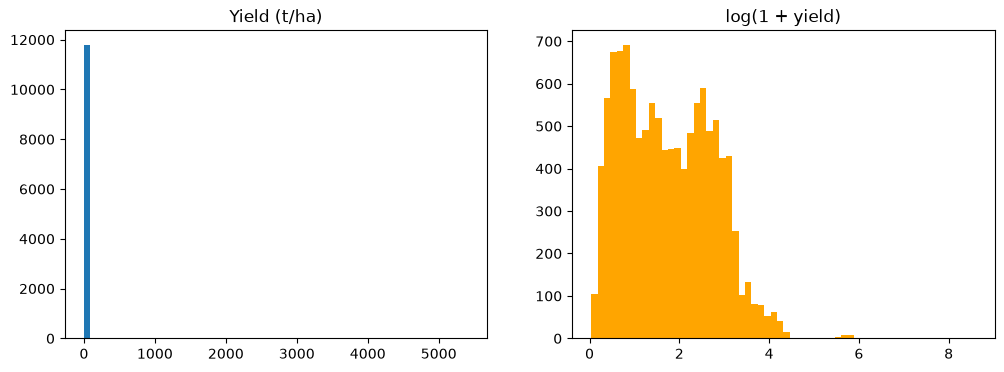

In [21]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df["yield_t_ha"], bins=60)
ax[0].set_title("Yield (t/ha)")

ax[1].hist(np.log1p(df["yield_t_ha"]), bins=60, color="orange")
ax[1].set_title("log(1 + yield)")

plt.show()

In [22]:
df[df["yield_t_ha"] > 100][["country", "crop", "year", "yield_t_ha"]]

,country,crop,year,yield_t_ha
3915,China,"Other stimulant, spice and aromatic crops, n.e.c.",1961,312.0000
3916,China,"Other stimulant, spice and aromatic crops, n.e.c.",1962,312.0000
3917,China,"Other stimulant, spice and aromatic crops, n.e.c.",1963,312.0000
3918,China,"Other stimulant, spice and aromatic crops, n.e.c.",1964,332.0000
3919,China,"Other stimulant, spice and aromatic crops, n.e.c.",1965,332.7000
3920,China,"Other stimulant, spice and aromatic crops, n.e.c.",1966,578.7667
3921,China,"Other stimulant, spice and aromatic crops, n.e.c.",1967,421.0682
3922,China,"Other stimulant, spice and aromatic crops, n.e.c.",1968,460.9000
3923,China,"Other stimulant, spice and aromatic crops, n.e.c.",1969,371.1400
3924,China,"Other stimulant, spice and aromatic crops, n.e.c.",1970,338.1818


In [23]:
#to remove the outliers 
print((df["yield_t_ha"] > 100).sum(), "rows to remove")   # expect 25
df = df[df["yield_t_ha"] <= 100].reset_index(drop=True)
print(df.shape)                                           # expect (11784, 12)
print(df["yield_t_ha"].max())                             # expect about 84.9

25 rows to remove
(11784, 12)
84.9063


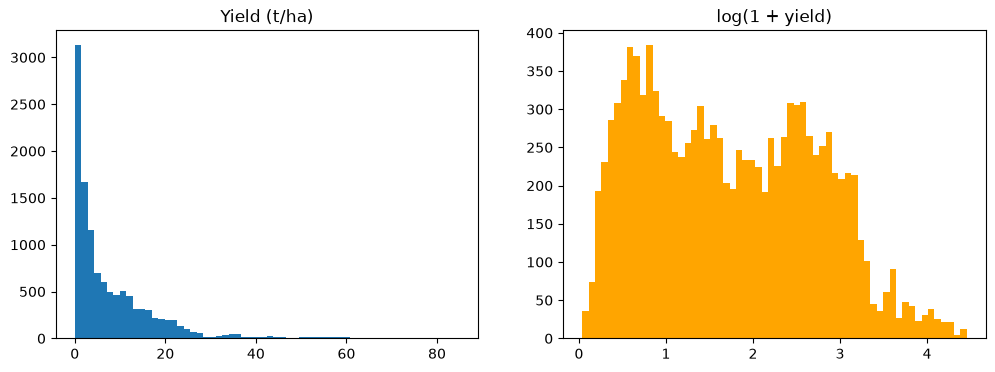

In [24]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df["yield_t_ha"], bins=60)
ax[0].set_title("Yield (t/ha)")

ax[1].hist(np.log1p(df["yield_t_ha"]), bins=60, color="orange")
ax[1].set_title("log(1 + yield)")

plt.show()

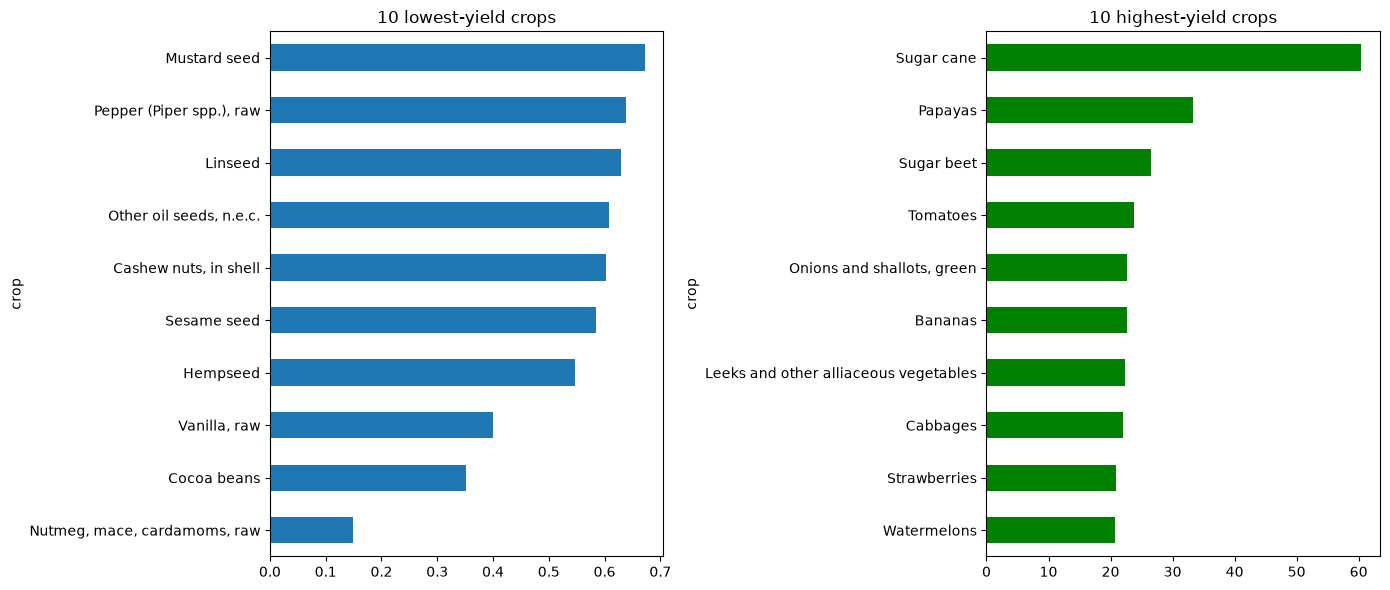

In [25]:
top = df.groupby("crop")["yield_t_ha"].mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top.head(10).plot.barh(ax=ax[0], title="10 lowest-yield crops")
top.tail(10).plot.barh(ax=ax[1], color="green", title="10 highest-yield crops")
plt.tight_layout()
plt.show()

In [26]:
"""
df.groupby("crop") splits the table into one group per crop: all the Rice rows together, all the Wheat rows together, and so on.
["yield_t_ha"] says to look only at the yield column inside each group.
.mean() calculates the average yield for each group, so each crop gets one number.
.sort_values() puts those averages in order, smallest first.
top = ... saves the result under the name top.

Example

crop	yield rows	average
Wheat	2.0, 2.5, 3.0	2.5
Sugar cane	60, 70, 80	70
Lentils	0.5, 0.7, 0.9	0.7

After the line runs, top is:

Lentils       0.7
Wheat         2.5
Sugar cane   70.0
"""

'\ndf.groupby("crop") splits the table into one group per crop: all the Rice rows together, all the Wheat rows together, and so on.\n["yield_t_ha"] says to look only at the yield column inside each group.\n.mean() calculates the average yield for each group, so each crop gets one number.\n.sort_values() puts those averages in order, smallest first.\ntop = ... saves the result under the name top.\n\nExample\n\ncrop\tyield rows\taverage\nWheat\t2.0, 2.5, 3.0\t2.5\nSugar cane\t60, 70, 80\t70\nLentils\t0.5, 0.7, 0.9\t0.7\n\nAfter the line runs, top is:\n\nLentils       0.7\nWheat         2.5\nSugar cane   70.0\n'

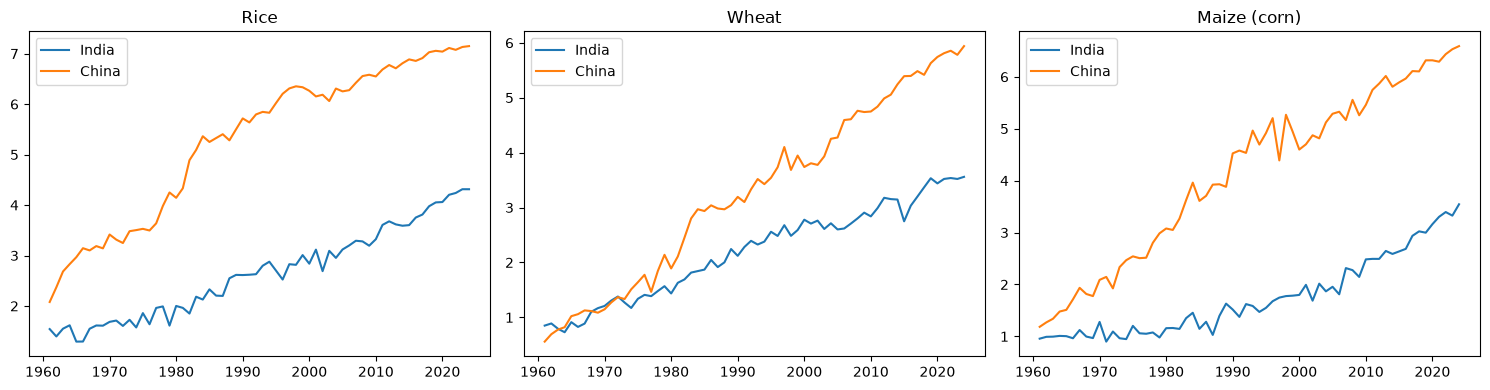

In [27]:
crops_to_plot = ["Rice", "Wheat", "Maize (corn)"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(crops_to_plot):
    for country in ["India", "China"]:
        d = df[(df["crop"] == c) & (df["country"] == country)]
        ax[i].plot(d["year"], d["yield_t_ha"], label=country)
    ax[i].set_title(c)
    ax[i].legend()
plt.tight_layout()
plt.show()

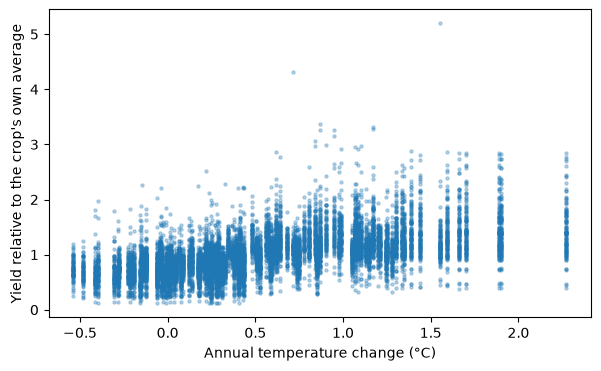

In [28]:
d = df.copy()
d["yield_rel"] = d["yield_t_ha"] / d.groupby(["country", "crop"])["yield_t_ha"].transform("mean")

plt.figure(figsize=(7, 4))
plt.scatter(d["temp_change_annual_c"], d["yield_rel"], s=5, alpha=0.3)
plt.xlabel("Annual temperature change (°C)")
plt.ylabel("Yield relative to the crop's own average")
plt.show()

In [29]:
"""
next step is feature engineering
"""

'\nnext step is feature engineering\n'

In [30]:
df

,country,crop,year,area_harvested_ha,yield_t_ha,production_t,yield_flag,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c
0,China,"Almonds, in shell",1985,7700.0,1.6883,1.300000e+04,E,-0.125,-0.351,-0.029,0.069,-0.188
1,China,"Almonds, in shell",1986,8300.0,1.6867,1.400000e+04,E,-0.040,0.133,0.120,0.047,-0.459
2,China,"Almonds, in shell",1987,8900.0,1.6854,1.500000e+04,E,0.433,1.585,0.074,-0.114,0.185
3,China,"Almonds, in shell",1988,8600.0,1.6860,1.450000e+04,E,0.400,0.906,-0.397,0.455,0.635
4,China,"Almonds, in shell",1989,9400.0,1.7021,1.600000e+04,E,0.432,1.181,0.343,-0.187,0.388
...,...,...,...,...,...,...,...,...,...,...,...,...
11779,India,Wheat,2020,31357020.0,3.4398,1.078605e+08,A,0.619,0.444,0.181,0.633,1.218
11780,India,Wheat,2021,31125160.0,3.5208,1.095865e+08,A,0.838,1.160,0.588,0.568,1.037
11781,India,Wheat,2022,30458530.0,3.5373,1.077421e+08,A,0.867,0.397,1.525,0.792,0.752
11782,India,Wheat,2023,31400716.0,3.5207,1.105537e+08,A,0.948,1.376,-0.070,1.033,1.452


In [31]:
#production_t = area * yield -> it already contains the answer
#yield_flag = just a data quality tag from FAO
df = df.drop(columns=["production_t", "yield_flag"])
print(df.columns.tolist())

['country', 'crop', 'year', 'area_harvested_ha', 'yield_t_ha', 'temp_change_annual_c', 'temp_change_djf_c', 'temp_change_mam_c', 'temp_change_jja_c', 'temp_change_son_c']


In [32]:
df

,country,crop,year,area_harvested_ha,yield_t_ha,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c
0,China,"Almonds, in shell",1985,7700.0,1.6883,-0.125,-0.351,-0.029,0.069,-0.188
1,China,"Almonds, in shell",1986,8300.0,1.6867,-0.040,0.133,0.120,0.047,-0.459
2,China,"Almonds, in shell",1987,8900.0,1.6854,0.433,1.585,0.074,-0.114,0.185
3,China,"Almonds, in shell",1988,8600.0,1.6860,0.400,0.906,-0.397,0.455,0.635
4,China,"Almonds, in shell",1989,9400.0,1.7021,0.432,1.181,0.343,-0.187,0.388
...,...,...,...,...,...,...,...,...,...,...
11779,India,Wheat,2020,31357020.0,3.4398,0.619,0.444,0.181,0.633,1.218
11780,India,Wheat,2021,31125160.0,3.5208,0.838,1.160,0.588,0.568,1.037
11781,India,Wheat,2022,30458530.0,3.5373,0.867,0.397,1.525,0.792,0.752
11782,India,Wheat,2023,31400716.0,3.5207,0.948,1.376,-0.070,1.033,1.452


In [33]:
print("skew raw :", df["yield_t_ha"].skew())
print("skew log :", np.log1p(df["yield_t_ha"]).skew())

skew raw : 2.705683863918379
skew log : 0.2756835754822908


In [34]:
#target selection #yield is skewed -> use log(1 + yield)
df["log_yield"] = np.log1p(df["yield_t_ha"])
#target = crop yield in tonnes per hectare (t/ha)
y = df["log_yield"]
print(y.describe())

count    11784.000000
mean         1.736622
std          0.985600
min          0.037488
25%          0.853457
50%          1.641721
75%          2.541289
max          4.453257
Name: log_yield, dtype: float64


In [35]:
print(df["area_harvested_ha"].describe())
print("skew:", df["area_harvested_ha"].skew())
print(df["area_harvested_ha"].median())

count    1.178400e+04
mean     1.807566e+06
std      5.385842e+06
min      1.200000e+01
25%      2.699900e+04
50%      2.099580e+05
75%      8.397442e+05
max      5.051193e+07
Name: area_harvested_ha, dtype: float64
skew: 5.0554314428418925
209958.0


In [36]:
#area is very skewed -> log(1 + area)
df["log_area"] = np.log1p(df["area_harvested_ha"])

print(df["log_area"].describe())
print("skew:", df["log_area"].skew())

count    11784.000000
mean        11.950656
std          2.590122
min          2.564949
25%         10.203592
50%         12.254668
75%         13.640854
max         17.737720
Name: log_area, dtype: float64
skew: -0.34320296182449817


In [37]:
#shouldnt drop are column even after transformoing it 
#Area is a useful clue. A crop grown on millions of hectares is
#usually a staple like rice or wheat,
#while a crop on a few hundred hectares is usually a niche spice.
#Knowing the area helps the model.

In [38]:
#sort so each crop's years are in order
df = df.sort_values(["country", "crop", "year"]).reset_index(drop=True)

df[["country", "crop", "year", "yield_t_ha","log_area"]]

,country,crop,year,yield_t_ha,log_area
0,China,"Almonds, in shell",1985,1.6883,8.949105
1,China,"Almonds, in shell",1986,1.6867,9.024131
2,China,"Almonds, in shell",1987,1.6854,9.093919
3,China,"Almonds, in shell",1988,1.6860,9.059634
4,China,"Almonds, in shell",1989,1.7021,9.148571
...,...,...,...,...,...
11779,India,Wheat,2020,3.4398,17.260949
11780,India,Wheat,2021,3.5208,17.253527
11781,India,Wheat,2022,3.5373,17.231877
11782,India,Wheat,2023,3.5207,17.262341


In [39]:
#inputs grouped by the predictor types in the problem statement
crop_geo = ["crop", "country"]                                   #crop + geographic
temporal = ["year"]                                              #temporal
weather  = ["temp_change_annual_c", "temp_change_djf_c",         #weather
            "temp_change_mam_c", "temp_change_jja_c", "temp_change_son_c"]
other    = ["log_area"]                                          #engineered

features = crop_geo + temporal + weather + other
target   = "log_yield"                                           #log(1 + yield in t/ha)

X = df[features]
y = df[target]

print("X:", X.shape)
print("y:", y.shape)
X.head()

X: (11784, 9)
y: (11784,)


,crop,country,year,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c,log_area
0,"Almonds, in shell",China,1985,-0.125,-0.351,-0.029,0.069,-0.188,8.949105
1,"Almonds, in shell",China,1986,-0.040,0.133,0.120,0.047,-0.459,9.024131
2,"Almonds, in shell",China,1987,0.433,1.585,0.074,-0.114,0.185,9.093919
3,"Almonds, in shell",China,1988,0.400,0.906,-0.397,0.455,0.635,9.059634
4,"Almonds, in shell",China,1989,0.432,1.181,0.343,-0.187,0.388,9.148571


In [40]:
#keep the useful columns: ids + inputs + target (+ raw yield for checking)
clean_cols = ["country", "crop", "year", "area_harvested_ha", "log_area",
              "temp_change_annual_c", "temp_change_djf_c", "temp_change_mam_c",
              "temp_change_jja_c", "temp_change_son_c",
              "yield_t_ha", "log_yield"]

df_clean = df[clean_cols]
df_clean.to_csv("cleaned_crop_yield.csv", index=False)

print(df_clean.shape)
print("missing:", df_clean.isna().sum().sum())
df_clean.head()

(11784, 12)
missing: 0


,country,crop,year,area_harvested_ha,log_area,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c,yield_t_ha,log_yield
0,China,"Almonds, in shell",1985,7700.0,8.949105,-0.125,-0.351,-0.029,0.069,-0.188,1.6883,0.988909
1,China,"Almonds, in shell",1986,8300.0,9.024131,-0.040,0.133,0.120,0.047,-0.459,1.6867,0.988314
2,China,"Almonds, in shell",1987,8900.0,9.093919,0.433,1.585,0.074,-0.114,0.185,1.6854,0.987830
3,China,"Almonds, in shell",1988,8600.0,9.059634,0.400,0.906,-0.397,0.455,0.635,1.6860,0.988053
4,China,"Almonds, in shell",1989,9400.0,9.148571,0.432,1.181,0.343,-0.187,0.388,1.7021,0.994029


In [41]:
#train = 1961-2014, test = 2015-2024 (last 10 years)
train = df[df["year"] <= 2014]
test  = df[df["year"] > 2014]

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print("train:", X_train.shape, train["year"].min(), "-", train["year"].max())
print("test :", X_test.shape,  test["year"].min(),  "-", test["year"].max())
print("test %:", round(len(test) / len(df) * 100, 1))

train: (9802, 9) 1961 - 2014
test : (1982, 9) 2015 - 2024
test %: 16.8


In [43]:
#turn text columns into 0/1 columns
X_train_enc = pd.get_dummies(X_train, columns=["crop", "country"], dtype=int)
X_test_enc  = pd.get_dummies(X_test,  columns=["crop", "country"], dtype=int)

#make test have exactly the same columns as train (missing ones = 0)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print("train:", X_train_enc.shape)
print("test :", X_test_enc.shape)

train: (9802, 134)
test : (1982, 134)


In [ ]:
#model 1 polynomial regression 

"""
1) standard scaling 
2) ridge lassso
3) 
"""


In [44]:
from sklearn.preprocessing import StandardScaler

num_cols = ["year", "log_area", "temp_change_annual_c", "temp_change_djf_c",
            "temp_change_mam_c", "temp_change_jja_c", "temp_change_son_c"]

scaler = StandardScaler()
X_train_enc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])   #learn from train
X_test_enc[num_cols]  = scaler.transform(X_test_enc[num_cols])        #apply to test

X_train_enc.head()

,year,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c,log_area,"crop_Almonds, in shell","crop_Anise, badian, coriander, cumin, caraway, fennel and juniper berries, raw",crop_Apples,...,crop_Triticale,"crop_True hemp, raw or retted",crop_Tung nuts,crop_Unmanufactured tobacco,"crop_Vanilla, raw","crop_Walnuts, in shell",crop_Watermelons,crop_Wheat,country_China,country_India
0,-0.247977,-1.108924,-1.129147,-0.678022,-0.466976,-1.010595,-1.128885,1,0,0,...,0,0,0,0,0,0,0,0,1,0
1,-0.183339,-0.929028,-0.501157,-0.441364,-0.514159,-1.482888,-1.100125,1,0,0,...,0,0,0,0,0,0,0,0,1,0
2,-0.118700,0.072036,1.382811,-0.514426,-0.859453,-0.360540,-1.073373,1,0,0,...,0,0,0,0,0,0,0,0,1,0
3,-0.054061,0.002194,0.501810,-1.262520,0.360873,0.423709,-1.086516,1,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0.010577,0.069919,0.858622,-0.087171,-1.016016,-0.006757,-1.052423,1,0,0,...,0,0,0,0,0,0,0,0,1,0


In [70]:
X_train_enc

,year,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c,log_area,"crop_Almonds, in shell","crop_Anise, badian, coriander, cumin, caraway, fennel and juniper berries, raw",crop_Apples,...,crop_Triticale,"crop_True hemp, raw or retted",crop_Tung nuts,crop_Unmanufactured tobacco,"crop_Vanilla, raw","crop_Walnuts, in shell",crop_Watermelons,crop_Wheat,country_China,country_India
0,-0.247977,-1.108924,-1.129147,-0.678022,-0.466976,-1.010595,-1.128885,1,0,0,...,0,0,0,0,0,0,0,0,1,0
1,-0.183339,-0.929028,-0.501157,-0.441364,-0.514159,-1.482888,-1.100125,1,0,0,...,0,0,0,0,0,0,0,0,1,0
2,-0.118700,0.072036,1.382811,-0.514426,-0.859453,-0.360540,-1.073373,1,0,0,...,0,0,0,0,0,0,0,0,1,0
3,-0.054061,0.002194,0.501810,-1.262520,0.360873,0.423709,-1.086516,1,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0.010577,0.069919,0.858622,-0.087171,-1.016016,-0.006757,-1.052423,1,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11769,1.367990,1.695325,0.557602,2.452538,1.188723,1.180073,2.020120,0,0,0,...,0,0,0,0,0,0,0,1,0,1
11770,1.432628,0.033940,-0.470017,-0.158645,0.015579,0.906457,2.028266,0,0,0,...,0,0,0,0,0,0,0,1,0,1
11771,1.497267,0.338704,-0.220897,0.292436,1.328127,0.014156,2.038563,0,0,0,...,0,0,0,0,0,0,0,1,0,1
11772,1.561906,0.175740,0.130725,0.411559,-0.587078,0.425451,2.035857,0,0,0,...,0,0,0,0,0,0,0,1,0,1


In [53]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Baseline: average yield of each crop + country (train years only)
avg = train.groupby(["country", "crop"])["yield_t_ha"].mean()
base_pred = test.set_index(["country", "crop"]).index.map(avg)
base_pred = pd.Series(base_pred).fillna(train["yield_t_ha"].mean()).values

#true test values in t/ha
y_test_real = np.expm1(y_test)

In [54]:
# ===== Step 7.2: Polynomial Regression =====
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

poly = PolynomialFeatures(degree=2, include_bias=False)
train_poly = poly.fit_transform(X_train_enc[num_cols])
test_poly  = poly.transform(X_test_enc[num_cols])

dummy_cols = [c for c in X_train_enc.columns if c not in num_cols]
X_train_poly = np.hstack([train_poly, X_train_enc[dummy_cols].values])
X_test_poly  = np.hstack([test_poly,  X_test_enc[dummy_cols].values])

poly_model = Ridge(alpha=1.0)
poly_model.fit(X_train_poly, y_train)
poly_pred = np.expm1(poly_model.predict(X_test_poly))

In [55]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_enc, y_train)
dt_pred = np.expm1(dt_model.predict(X_test_enc))

In [56]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
rf_model.fit(X_train_enc, y_train)
rf_pred = np.expm1(rf_model.predict(X_test_enc))

In [57]:
preds = {
    "Baseline":              base_pred,
    "Polynomial Regression": poly_pred,
    "Decision Tree":         dt_pred,
    "Random Forest":         rf_pred,
}

rows = []
for name, p in preds.items():
    rows.append([name,
                 mean_absolute_error(y_test_real, p),
                 mean_squared_error(y_test_real, p) ** 0.5,
                 r2_score(y_test_real, p)])

results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "R2"]).round(3)
results = results.sort_values("R2", ascending=False).reset_index(drop=True)
print(results)

                   Model    MAE   RMSE     R2
0          Random Forest  2.006  3.772  0.928
1          Decision Tree  1.851  3.973  0.920
2  Polynomial Regression  3.466  6.283  0.799
3               Baseline  4.303  8.044  0.671


In [58]:
#hold out the last 5 training years (2010-2014) to compare settings
#(the test years 2015-2024 stay untouched until the end)
val_mask = train["year"] >= 2010
X_tr, y_tr   = X_train_enc[~val_mask], y_train[~val_mask]
X_val, y_val = X_train_enc[val_mask],  y_train[val_mask]
y_val_real = np.expm1(y_val)

In [59]:
    #Block 1: Polynomial (try degree 1, 2, 3)

for d in [1, 2, 3]:
    pf = PolynomialFeatures(degree=d, include_bias=False)
    a = np.hstack([pf.fit_transform(X_tr[num_cols]), X_tr[dummy_cols].values])
    b = np.hstack([pf.transform(X_val[num_cols]),   X_val[dummy_cols].values])
    m = Ridge(alpha=1.0).fit(a, y_tr)
    print("degree", d, "-> R2:", round(r2_score(y_val_real, np.expm1(m.predict(b))), 3))

degree 1 -> R2: 0.761
degree 2 -> R2: 0.767
degree 3 -> R2: 0.715


In [61]:
 #Block 2: Decision Tree (try max_depth)

for depth in [5, 10, 20, None]:
    m = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_tr, y_tr)
    print("max_depth", depth, "-> R2:", round(r2_score(y_val_real, 
                                                        np.expm1(m.predict(X_val))), 3))

max_depth 5 -> R2: 0.258
max_depth 10 -> R2: 0.409
max_depth 20 -> R2: 0.588
max_depth None -> R2: 0.787


In [62]:
#Block 3: Random Forest (try n_estimators)
for n in [50, 100, 200]:
    m = RandomForestRegressor(n_estimators=n, n_jobs=-1, random_state=42).fit(X_tr, y_tr)
    print("n_estimators", n, "-> R2:", round(r2_score(y_val_real, np.expm1(m.predict(X_val))), 3))

n_estimators 50 -> R2: 0.842
n_estimators 100 -> R2: 0.847
n_estimators 200 -> R2: 0.849


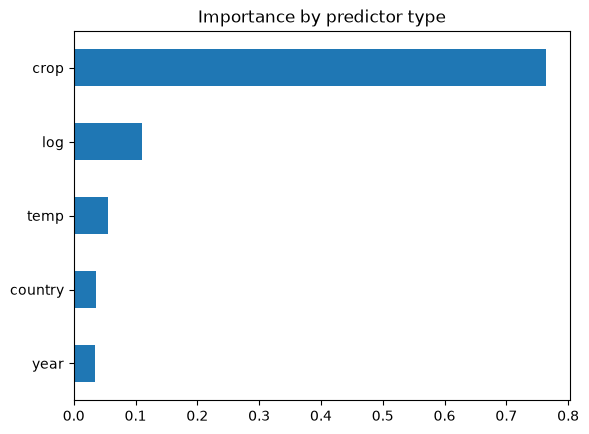

In [65]:
imp = pd.Series(rf_model.feature_importances_, index=X_train_enc.columns)
imp.groupby(imp.index.str.split("_").str[0]).sum().sort_values().plot.barh(title="Importance by predictor type")
plt.show()

In [66]:
err = test[["country", "crop", "year", "yield_t_ha"]].copy()
err["pred"]    = rf_pred                                         #Random Forest predictions
err["abs_err"] = (err["pred"] - err["yield_t_ha"]).abs()         #error in t/ha
err["pct_err"] = err["abs_err"] / err["yield_t_ha"] * 100        #error in %
err.head()

,country,crop,year,yield_t_ha,pred,abs_err,pct_err
30,China,"Almonds, in shell",2015,3.1927,2.868306,0.324394,10.160494
31,China,"Almonds, in shell",2016,3.2797,2.879307,0.400393,12.208215
32,China,"Almonds, in shell",2017,6.6763,2.822858,3.853442,57.718223
33,China,"Almonds, in shell",2018,3.3918,3.180896,0.210904,6.218063
34,China,"Almonds, in shell",2019,3.4469,3.166217,0.280683,8.143057


In [67]:
by_country = err.groupby("country").agg(
    rows=("abs_err", "size"),
    MAE=("abs_err", "mean"),
    pct_err=("pct_err", "median"),
)
by_country["R2"] = err.groupby("country").apply(lambda g: r2_score(g["yield_t_ha"], g["pred"]))
print(by_country.round(3))

         rows    MAE  pct_err     R2
country                             
China    1190  1.882    8.984  0.942
India     792  2.192   17.919  0.888


In [68]:
by_crop = err.groupby("crop").agg(
    rows=("pct_err", "size"),
    avg_yield=("yield_t_ha", "mean"),
    MAE=("abs_err", "mean"),
    pct_err=("pct_err", "median"),
).round(2)

#ignore crops with very few test rows (not reliable)
by_crop = by_crop[by_crop["rows"] >= 5]

print("10 HARDEST crops:")
print(by_crop.sort_values("pct_err", ascending=False).head(10))

print("\n5 EASIEST crops:")
print(by_crop.sort_values("pct_err").head(5))

10 HARDEST crops:
                              rows  avg_yield    MAE  pct_err
crop                                                         
Vanilla, raw                    10       0.16   0.41   258.97
Buckwheat                       10       0.81   0.57    63.38
Nutmeg, mace, cardamoms, raw    10       0.40   0.22    53.32
Cauliflowers and broccoli       20      19.43  10.61    46.60
Oranges                         20      17.14   6.61    44.14
Areca nuts                      20       2.08   0.84    44.01
Castor oil seeds                20       1.79   0.69    40.63
Sesame seed                     20       1.00   0.44    38.33
Okra                            10      12.17   4.37    37.84
True hemp, raw or retted        10       5.50   2.14    37.39

5 EASIEST crops:
              rows  avg_yield   MAE  pct_err
crop                                        
Olives          10       8.31  0.06     0.53
String beans    10      11.59  0.18     0.93
Tung nuts       10       2.62  0.03     

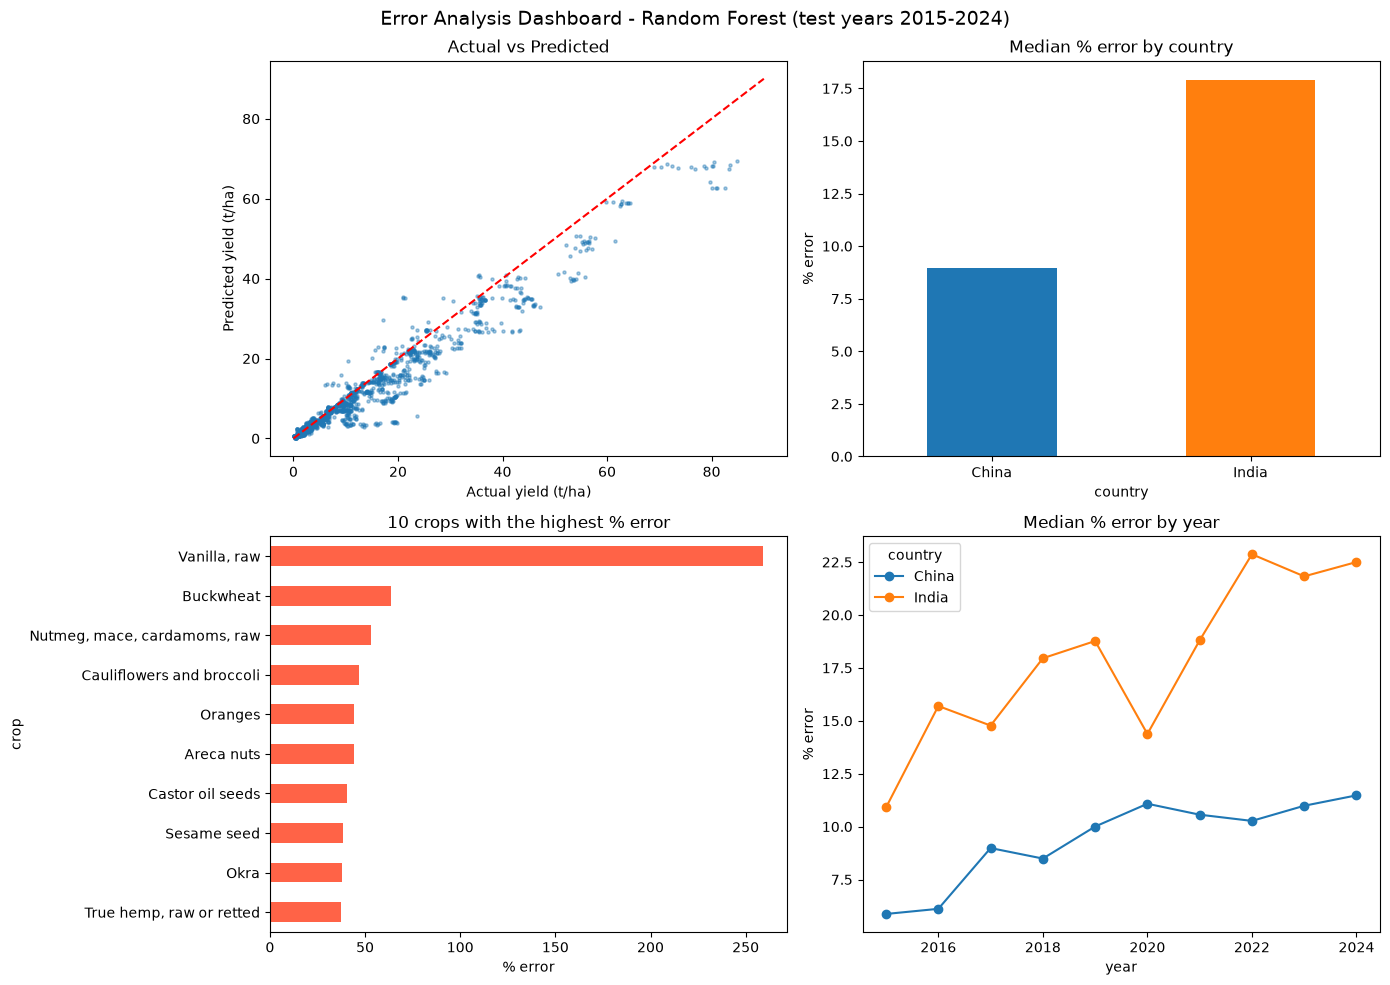

In [69]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Error Analysis Dashboard - Random Forest (test years 2015-2024)", fontsize=14)

#1. actual vs predicted
ax[0, 0].scatter(err["yield_t_ha"], err["pred"], s=5, alpha=0.4)
ax[0, 0].plot([0, 90], [0, 90], "r--")
ax[0, 0].set_title("Actual vs Predicted")
ax[0, 0].set_xlabel("Actual yield (t/ha)"); ax[0, 0].set_ylabel("Predicted yield (t/ha)")

#2. error by country
by_country["pct_err"].plot.bar(ax=ax[0, 1], color=["tab:blue", "tab:orange"], rot=0)
ax[0, 1].set_title("Median % error by country"); ax[0, 1].set_ylabel("% error")

#3. 10 hardest crops
by_crop.sort_values("pct_err", ascending=False).head(10)["pct_err"].plot.barh(ax=ax[1, 0], color="tomato")
ax[1, 0].invert_yaxis()
ax[1, 0].set_title("10 crops with the highest % error"); ax[1, 0].set_xlabel("% error")

#4. error over the test years
err.groupby(["year", "country"])["pct_err"].median().unstack().plot(ax=ax[1, 1], marker="o")
ax[1, 1].set_title("Median % error by year"); ax[1, 1].set_ylabel("% error")

plt.tight_layout()
plt.savefig("error_dashboard.png", dpi=120)
plt.show()